# Anytime-valid volatility monitor: a guided demo

This notebook walks through the prototype in five steps. Every output says whether it comes from **synthetic** (simulated) or **real** market data.

1. The estimators of Bapat (2026) on one real day, as printed and on a common scale.
2. Why the truncation constant matters: how much of the fourth moment survives clipping.
3. The monitor on a simulated path with known changes.
4. The monitor on real data: one month of ETH and two months of Nifty 50 around the 2024 election result.
5. A small check of the false alarm guarantee.

Run it from the repository root after `pip install -e .` (and `python scripts/download_data.py` for steps 1 and 4).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from avmonitor import robust as R
from avmonitor.monitor import VolatilityMonitor, GaussianLRMonitor
from avmonitor.data import load_binance, load_nifty, regular_sessions, intraday_scale, DATA_ROOT
HAVE_DATA = (DATA_ROOT / "crypto" / "binance" / "BTCUSDT").exists() and (DATA_ROOT / "nifty").exists()
print("real data files found:", HAVE_DATA)

real data files found: True


## 1. Estimators on one real day [real]

10 October 2025 was a crash day in crypto. The table gives each estimator of integrated quarticity (IQ) for that UTC day of Binance BTCUSDT one-minute returns, on the scale of eq. (3) with T = 1 day. The last row is the robust kernel estimator exactly as printed in eq. (16); it is on a different scale (see `docs/estimator_issues.md`), which is why it is many orders of magnitude smaller.

In [2]:
if HAVE_DATA:
    d = load_binance("BTCUSDT", "2025-10-10", "2025-10-11", download=False)
    r = d.logret.dropna().to_numpy()
    rows = {"RQ (eq. 3)": R.realized_quarticity(r), "TPQ": R.tripower_quarticity(r), "MinRQ": R.min_rq(r),
            "MedRQ": R.med_rq(r), "Threshold RQ": R.threshold_rq(r), "Kernel, normalised (h = 30)": R.kernel_iq(r, 30),
            "Robust kernel, normalised, scaled MAD": R.kernel_iq(r, 30, c=3, mad_scaled=True),
            "  ... with the kappa_4 correction": R.kernel_iq(r, 30, c=3, mad_scaled=True, bias_correct=True),
            "Robust kernel as printed (eq. 16, raw MAD)": R.robust_kernel_quarticity_printed(r, 30, 3.0)}
    display(pd.Series(rows, name="IQ, BTCUSDT 2025-10-10 [real]").to_frame().style.format("{:.3g}"))
else:
    print("skipped: run scripts/download_data.py first")

,"IQ, BTCUSDT 2025-10-10 [real]"
RQ (eq. 3),0.00205
TPQ,0.000429
MinRQ,0.000157
MedRQ,0.000502
Threshold RQ,9.54e-06
"Kernel, normalised (h = 30)",0.00209
"Robust kernel, normalised, scaled MAD",3.45e-07
... with the kappa_4 correction,3.58e-07
"Robust kernel as printed (eq. 16, raw MAD)",5.59e-13


## 2. How much of the fourth moment survives truncation [theory]

Eq. (11) clips returns at c times the MAD. If the MAD is not multiplied by 1.4826, c = 3 clips at about 2 standard deviations and keeps only about 70% of the fourth moment, at every sample size. With the scaled MAD it keeps about 96%.

In [3]:
tab = pd.DataFrame([dict(c=c, MAD=m, cutoff_in_sd=R.effective_cutoff(c, m == "scaled"),
                         fourth_moment_kept=R.truncated_moment_factor(R.effective_cutoff(c, m == "scaled"), 4))
                    for c in (2, 3, 4, 5) for m in ("raw", "scaled")])
tab.round(3)

,c,MAD,cutoff_in_sd,fourth_moment_kept
0,2,raw,1.349,0.322
1,2,scaled,2.000,0.693
2,3,raw,2.023,0.705
3,3,scaled,3.000,0.964
4,4,raw,2.698,0.923
5,4,scaled,4.000,0.999
6,5,raw,3.372,0.988
7,5,scaled,5.000,1.000


## 3. The monitor on a simulated path [synthetic]

Volatility rises by 50% at step 3000 and falls back at step 6000. Rare large jumps occur at the same rate throughout, so they are part of normal behaviour. The robust monitor should alarm near the two true changes; the Gaussian likelihood-ratio monitor, which assumes normal returns, also reacts to the jumps.

robust  : [(3020, 'up'), (6145, 'down'), (8308, 'down')]
Gaussian: [(1000, 'up'), (2564, 'up'), (3581, 'up'), (4779, 'up'), (6066, 'down'), (7570, 'up'), (8823, 'up')]


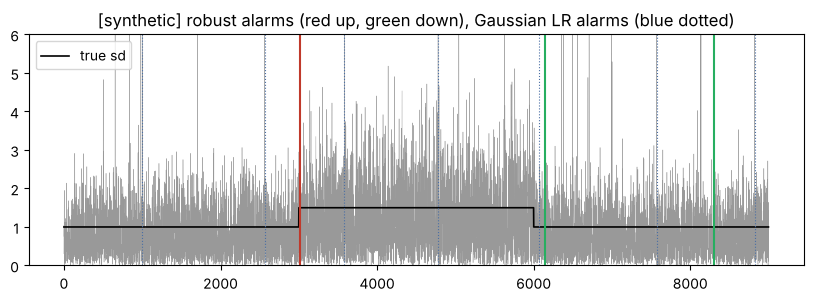

In [4]:
rng = np.random.default_rng(42)
n = 9000; sd = np.ones(n); sd[3000:6000] = 1.5
r = sd * rng.standard_normal(n) + (rng.random(n) < 0.003) * rng.normal(0, 10, n)
rob = VolatilityMonitor(threshold=7800, cal_len=1000).run(r)
gau = GaussianLRMonitor(threshold=7800, cal_len=1000).run(r)
print("robust  :", [(e.index, e.direction) for e in rob])
print("Gaussian:", [(e.index, e.direction) for e in gau])
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(np.abs(r), lw=0.3, color="#999"); ax.plot(sd, "k", lw=1.2, label="true sd")
for e in rob: ax.axvline(e.index, color="#c0392b" if e.direction == "up" else "#27ae60", lw=1.5)
for e in gau: ax.axvline(e.index, color="#4a6fa5", lw=0.8, ls=":")
ax.set_ylim(0, 6); ax.set_title("[synthetic] robust alarms (red up, green down), Gaussian LR alarms (blue dotted)"); ax.legend(); plt.show()

## 4. The monitor on real data [real]

Returns are divided by a predictable intraday volatility profile (median absolute return at each minute of the day over the previous 20 days), then monitored with a 5% false alarm budget per day and a null band of 0.25 (changes smaller than 25% in variance are not flagged). After each alarm the monitor recalibrates on fresh data.

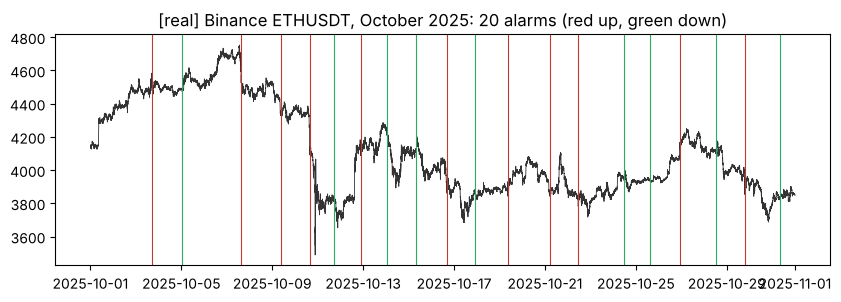

,time,direction
0,2025-10-03 17:02:00+00:00,up
1,2025-10-05 00:38:00+00:00,down
2,2025-10-07 15:06:00+00:00,up
3,2025-10-09 08:51:00+00:00,up
4,2025-10-10 15:21:00+00:00,up
5,2025-10-11 17:02:00+00:00,down
6,2025-10-12 21:34:00+00:00,up
7,2025-10-14 00:57:00+00:00,down
8,2025-10-15 07:43:00+00:00,down
9,2025-10-16 16:48:00+00:00,up


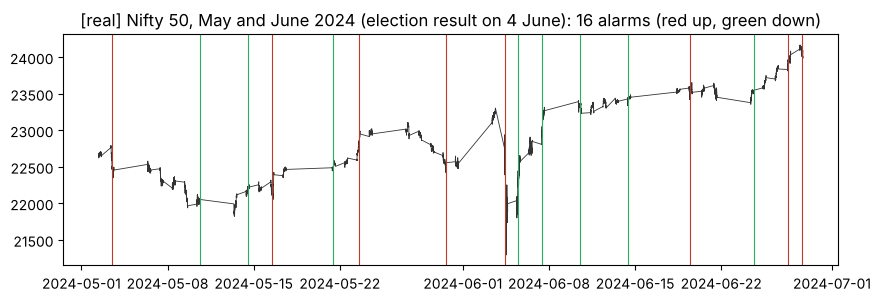

,time,direction
0,2024-05-03 10:42:00+05:30,up
1,2024-05-10 15:23:00+05:30,down
2,2024-05-14 13:37:00+05:30,down
3,2024-05-16 12:09:00+05:30,up
4,2024-05-21 10:25:00+05:30,down
5,2024-05-23 13:25:00+05:30,up
6,2024-05-30 15:27:00+05:30,up
7,2024-06-04 09:24:00+05:30,up
8,2024-06-05 10:48:00+05:30,down
9,2024-06-07 09:42:00+05:30,down


In [5]:
def run_and_plot(df, spd, title):
    s = intraday_scale(df.logret.fillna(0.0), lookback_days=20)
    u = (df.logret / s).to_numpy()
    ev = VolatilityMonitor(threshold=spd / 0.05, cal_len=spd, null_band=0.25).run(np.where(np.isfinite(u), u, np.nan))
    fig, ax = plt.subplots(figsize=(10, 3))
    ax.plot(df.index, df.close, lw=0.6, color="#333")
    for e in ev: ax.axvline(df.index[e.index], color="#c0392b" if e.direction == "up" else "#27ae60", lw=0.8)
    ax.set_title(title + f": {len(ev)} alarms (red up, green down)"); plt.show()
    return pd.DataFrame([dict(time=df.index[e.index], direction=e.direction) for e in ev])

if HAVE_DATA:
    eth = load_binance("ETHUSDT", "2025-10-01", "2025-11-01", download=False)
    display(run_and_plot(eth, 1440, "[real] Binance ETHUSDT, October 2025").head(10))
    nifty = regular_sessions(load_nifty("2024-05-01", "2024-07-01", download=False))
    display(run_and_plot(nifty, 375, "[real] Nifty 50, May and June 2024 (election result on 4 June)"))
else:
    print("skipped: run scripts/download_data.py first")

## 5. The false alarm guarantee, checked [synthetic]

With the true baseline, Theorem B (`docs/math.md`, 5.4) says the chance of any false alarm within m steps is at most m / A. Here: Student t returns with 3 degrees of freedom (no finite fourth moment), A = 7800, one 390-step day, 2000 paths. The bound is 5%. Experiment E9 runs this at a larger scale for several distributions.

In [6]:
from avmonitor.detectors import betting_edetector, two_sided_alarm
rng = np.random.default_rng(7)
big = rng.standard_t(3, 5_000_000); tau = 3 * np.median(np.abs(big)) * R.MAD_NORMAL_SCALE
m0 = np.minimum(big**2, tau**2).mean()
x = np.minimum(rng.standard_t(3, (2000, 390))**2, tau**2)
a = two_sided_alarm(betting_edetector(x, m0, "up", threshold=2 * 7800),
                    betting_edetector(x, m0, "down", upper=tau**2, threshold=2 * 7800))
print(f"[synthetic] share of days with a false alarm: {np.mean(a >= 0):.3f} (bound 0.05)")

[synthetic] share of days with a false alarm: 0.015 (bound 0.05)


## Where to go next

* `docs/experiment_report.md`: every experiment, with tables and caveats.
* `docs/math.md`: definitions and proofs. `docs/equation_map.md`: each equation of the paper and where it lives in the code.
* `PITCH_BAPAT.md`: the short version, with questions for the author.
* Command line: `python -m avmonitor run --source binance --symbol SOLUSDT --start 2025-07-01 --end 2025-08-01 --plot sol.png`.